source   
<a href='https://ourworldindata.org/grapher/annual-co2-emissions-per-country?country=USA~GBR~IND~CHN'>https://ourworldindata.org/grapher/annual-co2-emissions-per-country?country=USA~GBR~IND~CHN</a></br>
<a href='https://ourworldindata.org/grapher/temperature-anomaly?tab=table&time=1850..2026'>https://ourworldindata.org/grapher/temperature-anomaly?tab=table&time=1850..2026</a></br>
<a href="https://ourworldindata.org/energy-production-consumption">https://ourworldindata.org/energy-production-consumption</a>  
<a href='https://www.worldometers.info/world-population/world-population-by-year'>https://www.worldometers.info/world-population/world-population-by-year</a>


In [1]:
import pandas as pd
import numpy as np
import requests
import json
import sqlite3 as sql
from matplotlib import pyplot as plt
import seaborn as sns
PATH = '../../../Databases/world/'

In [2]:
def query(q, source='CO2_emission_1750-2024.sql'):
    with sql.connect(PATH+source) as conn:
        df = pd.read_sql(q, conn)
    return df

def execute(q, source='CO2_emission_1750-2024.sql'):
    with sql.connect(PATH+source) as conn:
        conn.execute(q)

    return 'done'

#### Ref:
[Plots: Emission and warming](#Analysis)  
[Plots: Total emission in periods](#Total_global_in_periods)  
[Plots: countries total emission](#Countries_total_emission)  
[Plots: USA, CHina, India](#USA_Chn_Ind_emission)  
[Plots: Top 15 in periods](#Top_15_in_periods)  
[Plots: Population vs pollution](#Population)  
[Tables: Pollution increase](#Polution_increase)  
[Plots: Emission development](#Emission)  
[Plots: Income-pollution disparity](#Income)  
[Calc: USA](#usa)  
[Calc: global temparature](#Temperature)

#### Analysis

In [3]:
q = """SELECT * FROM sqlite_master"""
query(q)

,type,name,tbl_name,rootpage,sql
0,table,CO2,CO2,2,"CREATE TABLE ""CO2"" (\n""entity"" TEXT,\n ""code""..."
1,view,owid,owid,0,CREATE VIEW owid AS\n\nSELECT * FROM CO2 WHERE...
2,view,couns_full,couns_full,0,CREATE VIEW couns_full AS\n\nSELECT * FROM CO2...
3,table,countries,countries,4,"CREATE TABLE ""countries"" (\n""entity"" TEXT,\n ..."
4,table,groups,groups,9,"CREATE TABLE ""groups"" (\n""entity"" TEXT,\n ""em..."
5,table,sea_level,sea_level,10,"CREATE TABLE ""sea_level"" (\n""year"" INTEGER,\n ..."


In [13]:
q ="""SELECT COUNT(DISTINCT(code)) as 'No of countries' FROM couns_full """
query(q)

,No of countries
0,215


In [3]:
q = """SELECT * FROM 'owid' WHERE entity = 'World'"""
world = query(q)
world.iloc[[0,-2,-1]]

,entity,code,year,emissions_total
0,World,OWID_WRL,1750,9.305937e+06
273,World,OWID_WRL,2023,3.809404e+10
274,World,OWID_WRL,2024,3.859858e+10


In [4]:
# convert to Gt from tonne
world.emissions_total = world.emissions_total / 10**9

In [53]:
# pollution increase in ratio from 23 to 24
(world.loc[world.year == 2024, 'emissions_total'].values - world.loc[world.year == 2023, 'emissions_total'].values) / world.loc[world.year == 2023, 'emissions_total'].values

array([0.01324459])

In [54]:
# first year pollution got above natural fixation level
world['above'] = world.emissions_total - 18
world.loc[world['above'] > 0][:2]

,entity,code,year,emissions_total,above
227,World,OWID_WRL,1977,18.358039,0.358039
228,World,OWID_WRL,1978,19.024742,1.024742


In [58]:
#total CO2 excess production and the years needed to clear up
excess = world.loc[world['above'] > 0, 'above'].sum()
print('excess CO2 [Gt]: ', excess)
print('clearing years: ', round((excess / 18), 2))

excess CO2 [Gt]:  458.842803
clearing years:  25.49


In [60]:
q = """SELECT Entity as ent, Year as year,
Average as avg from temp Where ent = 'World'"""
temp = query(q,source='Global_temperature_change_1850-2026.sql')

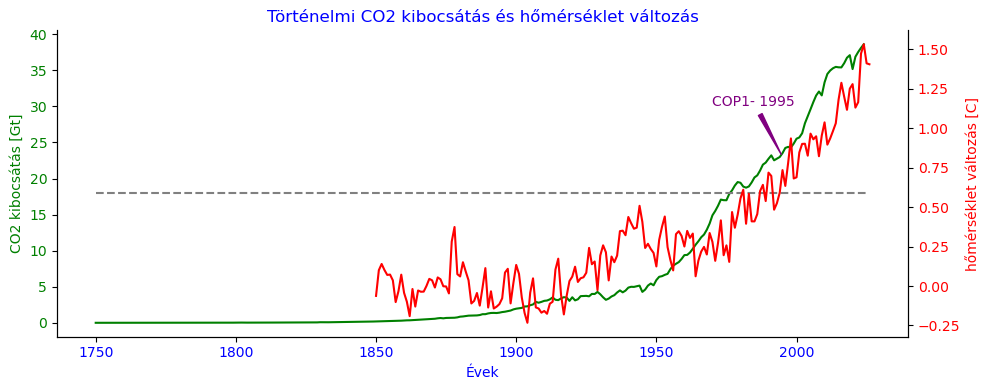

In [67]:
fig, ax1 = plt.subplots(figsize=(10,4))
ax1.set_xlabel('Years', color='blue')
ax1.set_xlabel('Évek', color='blue')
ax1.set_ylabel('CO2 emission [Gton]',color='green')
ax1.set_ylabel('CO2 kibocsátás [Gt]',color='green')
ax1.plot(world.year, world.emissions_total, color='green')

ax1.hlines(y=18, xmin=1750, xmax=2025, color='grey', linestyle='dashed')
ax1.spines['top'].set_visible(False)
ax1.tick_params(axis='y',labelcolor='green')
ax1.tick_params(axis='x', labelcolor='blue')
ax2 = ax1.twinx()
ax2.plot(temp.year, temp.avg, color='red')
ax2.set_ylabel('temperature change [C]', color='red')
ax2.set_ylabel('hőmérséklet változás [C]', color='red')
ax2.spines['top'].set_visible(False)
ax2.tick_params(axis='y', labelcolor='red')

ax1.annotate(xy=(1995,23), text='COP1- 1995', xytext=(1970,30), size=10, color='purple',
            arrowprops=dict(arrowstyle="wedge", color='purple'))

#ax1.annotate(xy=(1750, 18.5), text='Natural absopsion level', size=10, color='grey')
ax1.annotate(xy=(1750, 1.85*10**10), text='Természetes megkötési kapacitás', size=10, color='grey')
plt.title('Correlation of Historical World CO2 emission and Global Temperature change', color='blue')
plt.title('Történelmi CO2 kibocsátás és hőmérséklet változás', color='blue')
plt.tight_layout()
plt.savefig('fullperiod_hu.png', dpi=120)
plt.show()

### Total_global_in_periods

In [68]:
world_1750 = world.loc[world.year < 1950]
wtot_1750 = world_1750.emissions_total.sum()

In [69]:
# How many years of the latest emissions are equal to the first 200?
tot = 0
n = -1
while wtot_1750 > tot:
    
    tot = world.iloc[n:]['emissions_total'].sum()
    n-=1
n+1

-7

In [70]:
tot, wtot_1750

(np.float64(260.066061), np.float64(225.95970254899999))

In [71]:
s90 = world.loc[(world.year >=1950) & (world.year < 1994), 'emissions_total'].sum()
s20 = world.loc[(world.year >=1995) & (world.year < 2018), 'emissions_total'].sum()

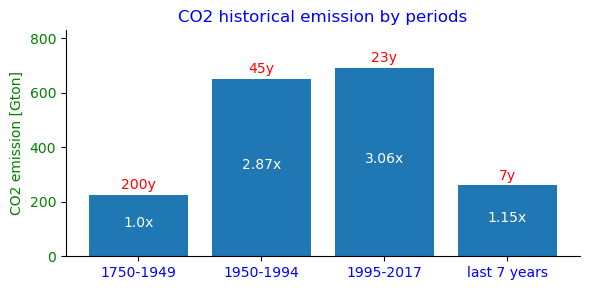

In [79]:
ax = plt.subplot()
plt.rcParams['figure.figsize'] = (6,3)
xtick = ['1750-1949', '1950-1994','1995-2017', 'last 7 years']
#xtick = ['1750-1949', '1950-1994','1995-2017', 'utolsó 7 év']
f1 = ax.bar(xtick,[wtot_1750, s90, s20, tot])
ax.set_title('CO2 historical emission by periods', c='blue')
#ax.set_title('Történelmi periódusok CO2 kibocsátása', c='blue')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='x', labelcolor='blue')
ax.tick_params(axis='y', labelcolor='green')

plt.ylabel('CO2 emission [Gton]', color='green')
#plt.ylabel('CO2 kibocsátás [Gt]', color='green')
plt.rcParams['figure.figsize'] = (6,3)
ax.bar_label(f1, labels=['200y','45y','23y', '7y'],fmt='%.2f', padding=2.0, color='red')
#ax.bar_label(f1, labels=['200év','45év','23év', '7év'],fmt='%.2f', padding=2.0, color='red')
ax.bar_label(f1, label_type='center', labels=[str(wtot_1750/wtot_1750)+'x',str(round(s90/wtot_1750,2))+'x',str(round(s20/wtot_1750,2))+'x', str(round(tot/wtot_1750,2))+'x'],fmt='%.2f', padding=2.0, color='white')
ax.set_ylim(top=s20*1.2)
plt.tight_layout()
plt.savefig('periods.png', dpi=120)
plt.show()

### Countries_total_emission 

In [26]:
q = """SELECT * FROM countries"""
countries = query(q)
countries.shape

(215, 5)

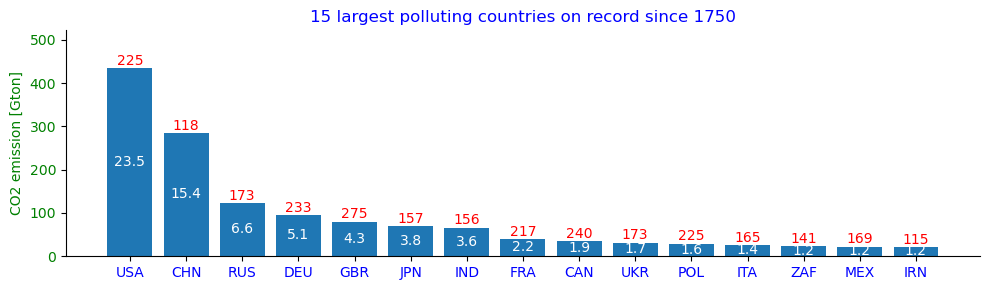

In [83]:
top15em = countries.sort_values('emissions_total', ascending=False)[:15].reset_index()
top15em.emissions_total = top15em.emissions_total / 10**9

fig, ax = plt.subplots(figsize=(10,3))
f2 = ax.bar(top15em.code, top15em['emissions_total'])
ax.bar_label(f2, top15em['world_%'].round(1), label_type='center', fmt='%.2f', padding=0.2, color='white')
ax.bar_label(f2, top15em['count'], label_type='edge', fmt='%.2f', padding=0.2, color='red')
ax.set_ylim(top=top15em['emissions_total'].max()*1.2)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='x', labelcolor='blue')
ax.tick_params(axis='y', labelcolor='green')
plt.ylabel('CO2 emission [Gton]',c='green')
#plt.ylabel('CO2 kibocsátás [Gt]',c='green')
plt.title('15 largest polluting countries on record since 1750', c='blue')
#plt.title('15 legnagyobb szennyező ország 1750 óta', c='blue')
plt.tight_layout()
plt.savefig('top15.png', dpi=120)
plt.show()

### USA_Chn_Ind_emission

In [107]:
q = """SELECT   
usa.emissions_total as USA,
usa.year as year,
ch.emissions_total as China,
ind.emissions_total as India,
rus.emissions_total as Russia
FROM
(SELECT * FROM CO2 WHERE code ='USA') AS usa
LEFT JOIN
(SELECT * FROM CO2 WHERE code = 'CHN') AS ch
ON usa.year = ch.year
LEFT JOIN 
(SELECT year, emissions_total FROM CO2 WHERE code = 'IND') as ind
ON usa.year = ind.year
LEFT JOIN
(SELECT year, emissions_total FROM CO2 WHERE code = 'RUS') as rus
ON usa.year = rus.year
;"""
c3 = query(q)

In [108]:
c3.index = c3['year']

In [109]:
c3.drop('year', axis=1, inplace=True)
c3 = c3 / 10**9

In [110]:
c3 = c3.iloc[50:]

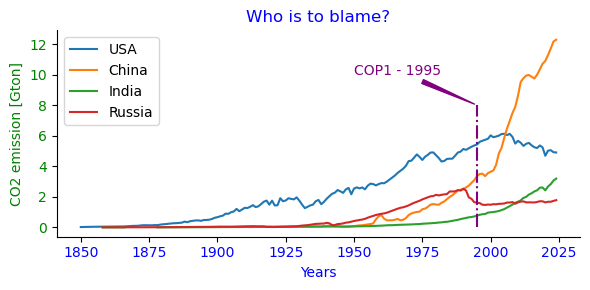

In [113]:
plt.rcParams['figure.figsize'] = (6,3)
ax = plt.subplot()
for c in c3.columns:
    ax.plot(c3.index, c3[c])

ax.vlines(1995, ymin=0, ymax=8, color='purple', linestyle='dashdot')
ax.annotate(text='COP1 - 1995', xy=(1995,8), xytext=(1950,10), color='purple',
           arrowprops=dict(arrowstyle='wedge', color='purple'))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='y', labelcolor='green')
plt.ylabel('CO2 emission [Gton]', color='green')
#plt.ylabel('CO2 kibocsátás [Gt]', color='green')
plt.xticks(color='blue')
plt.xlabel(('Years'), color='blue')
#plt.xlabel(('Évek'), color='blue')
plt.title('Who is to blame?', color='blue')
#plt.title('Ki a bűnös?', color='blue')
plt.legend(c3.columns)
#plt.legend(['USA','Kína','India','Oroszo.'])
plt.tight_layout()
plt.savefig('whotoblame.png', dpi=120)
plt.show()

### Top_15_in_periods

In [115]:
q = "SELECT code, year, emissions_total FROM couns_full WHERE year < 1950;"
e1950 = query(q)

In [116]:
e50top = e1950.groupby('code').agg({'emissions_total': ['sum','count']}).sort_values(('emissions_total',   'sum'), ascending=False)[:15]
e50top.columns = ['emissions_total', 'count']
e50top.emissions_total = e50top.emissions_total / 10**9

In [117]:
q = "SELECT code, year, emissions_total FROM couns_full WHERE year > 1949 AND year < 1995; "
e95 = query(q)
e95top = e95.groupby('code').agg({'emissions_total': 'sum'}).sort_values('emissions_total', ascending=False)[:15]
e95top.emissions_total = e95top.emissions_total / 10**9

In [118]:
q = "SELECT code, year, emissions_total FROM couns_full WHERE year > 1994 AND year < 2018; "
e17 = query(q)
e17top = e17.groupby('code').agg({'emissions_total': 'sum'}).sort_values('emissions_total', ascending=False)[:15]
e17top.emissions_total = e17top.emissions_total / 10**9

In [119]:
q = "SELECT code, year, emissions_total FROM couns_full WHERE year > 2017; "
e8 = query(q)
e8top = e8.groupby('code').agg({'emissions_total': 'sum'}).sort_values('emissions_total', ascending=False)[:15]
e8top.emissions_total = e8top.emissions_total / 10**9

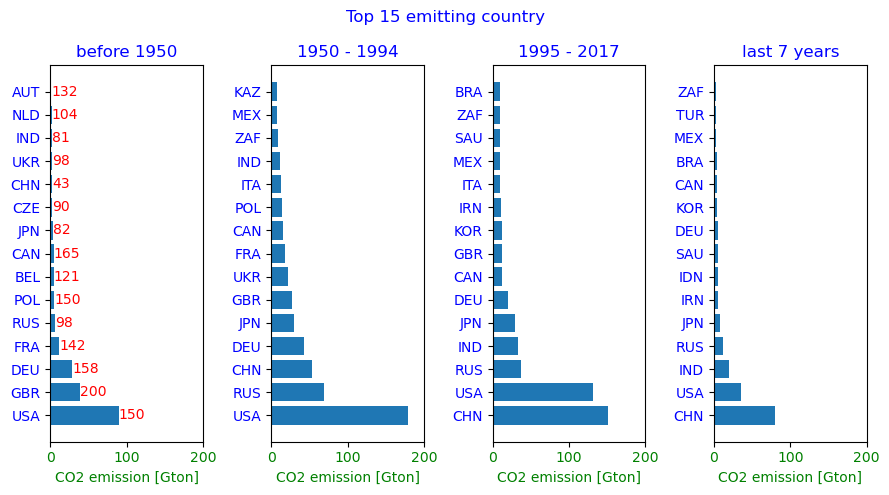

In [126]:
plt.rcParams['figure.figsize'] = (9,5)
ax1 = plt.subplot2grid((1,4),(0,0))
ax2 = plt.subplot2grid((1,4),(0,1))
ax3 = plt.subplot2grid((1,4),(0,2))
ax4 = plt.subplot2grid((1,4),(0,3))

axes = [ax1,ax2,ax3,ax4]

f4 = ax1.barh(y=e50top.index, width=e50top.emissions_total)
ax2.barh(y=e95top.index, width=e95top.emissions_total)
ax3.barh(y=e17top.index, width=e17top.emissions_total)
ax4.barh(y=e8top.index, width=e8top.emissions_total)

ax1.bar_label(f4, e50top['count'], c='red')

for ax in axes:
    ax.set_xlabel('CO2 emission [Gton]', c='green')
    #ax.set_xlabel('CO2 kibocsátás [Gt]', c='green')
    ax.set_yticks(range(15))
    ax.set_yticklabels(ax.get_yticklabels(), c='blue')
    ax.set_xlim(right=200)
    ax.tick_params(axis='x', labelcolor='green')
    
ax1.set_title('before 1950', c='blue')
#ax1.set_title('1950 elött', c='blue')
ax2.set_title('1950 - 1994', c='blue')
ax3.set_title('1995 - 2017', c='blue')
ax4.set_title('last 7 years', c='blue')
#ax4.set_title('utolsó 7 év', c='blue')

plt.suptitle('Top 15 emitting country', c='blue')
#plt.suptitle('15 legszennyezőbb ország', c='blue')
plt.tight_layout()
plt.savefig('top15periods.png', dpi=120)
plt.show()

### Population

In [127]:
with open(PATH+'world_population_2026.json', 'r') as f:
    dic = json.load(f)

In [49]:
dic['meta']

'source: https://www.worldometers.info/world-population/world-population-by-year'

In [129]:
dic.pop('meta')

'source: https://www.worldometers.info/world-population/world-population-by-year'

In [131]:
poo = pd.DataFrame(dic)
poo.population = poo.population.astype(int)
poo1750 = poo.loc[(poo.year > 1750)]
poo1750.population = poo1750.population / 10**9

/tmp/ipykernel_5484/2107831042.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  poo1750.population = poo1750.population / 10**9


In [134]:
poo1750

,year,population,change%,net_change,density
0,2026,8.300678,0.84,69065325,56
1,2025,8.231613,0.85,69640498,55
2,2024,8.161973,0.87,70237642,55
3,2023,8.091735,0.88,70327738,54
4,2022,8.021407,0.84,66958801,54
...,...,...,...,...,...
77,1927,2.000000,–,–,13
78,1900,1.600000,–,–,11
79,1850,1.200000,–,–,8
80,1804,1.000000,–,–,7


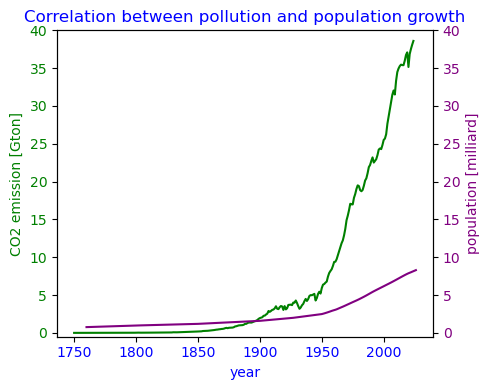

In [140]:
plt.rcParams['figure.figsize'] =(5,4)
ax1 = plt.subplot(1,1,1)
ax2 = plt.subplot(1,1,1)
ax1.plot(world.year, world.emissions_total, c='green')
ax1.tick_params(axis='y', labelcolor='green')
ax1.tick_params(axis='x', labelcolor='blue')
ax1.set_ylabel('CO2 emission [Gton]', c='green')
ax1.set_xlabel('year', c='blue')
#ax1.set_ylabel('CO2 kibocsátás [Gt]', c='green')
#ax1.set_xlabel('év', c='blue')
ax1.set_ylim(bottom=-0.5,top=40)

ax2 =ax1.twinx()
ax2.plot(poo1750.year, poo1750.population, c='purple')
ax2.tick_params(axis='y', labelcolor='purple')
ax2.set_ylabel('population [milliard]', c='purple')
#ax2.set_ylabel('népesség [milliárd]', c='purple')
ax2.set_ylim(bottom=-0.5,top=40)

plt.title('Correlation between pollution and population growth', c='blue')
#plt.title('Szénnyezés és a népesség növekedés kapcsolata', c='blue')
plt.tight_layout()
plt.savefig('population.png', dpi=120)
plt.show()

In [141]:
py = poo.loc[poo.year.isin([1950, 2024]), ['year','population']] 
wy = world.loc[world.year.isin([1950,2024]), ['year','emissions_total']]
wp = pd.merge(wy,py, how='left', left_on='year', right_on='year')

In [142]:
wp

,year,emissions_total,population
0,1950,5.930406,2493092848
1,2024,38.598580,8161972572


In [54]:
#emission-population ratio
wp.emissions_total / wp.population

0    2.378735
1    4.729075
dtype: float64

### Polution_increase

In [143]:
q = """SELECT sql FROM sqlite_master WHERE name = 'CO2';"""
print(query(q).values[0][0])

CREATE TABLE "CO2" (
"entity" TEXT,
  "code" TEXT,
  "year" INTEGER,
  "emissions_total" REAL
)


In [144]:
q = """SELECT 
e.entity as country,
e.code as code,
e.emissions_total as '2023',
l.emissions_total as '2024'
FROM 
(SELECT * FROM couns_full WHERE year = 2023) as e
LEFT JOIN
(SELECT * FROM couns_full WHERE year = 2024) as l
on e.code = l.code
;"""
ch = query(q)

In [145]:
q = """SELECT emissions_total FROM owid WHERE entity = 'World' AND year = 2023;"""
world23 = query(q)
world23 = round(world23.values[0][0] / 10**9, 3)
world23

np.float64(38.094)

In [146]:
q = """SELECT emissions_total FROM owid WHERE entity = 'World' AND year = 2024;"""
world24 = query(q)
world24 = round(world24.values[0][0] / 10**9, 3)
world24

np.float64(38.599)

In [147]:
ch['change'] = ch['2024'] - ch['2023']

In [148]:
ch['change%'] = (ch['change']/ch['2023'])*100

In [149]:
ch = ch.sort_values('2024', ascending=False).reset_index(drop=True)

In [150]:
ch1 = ch.copy()

In [151]:
ch1['2023'] = round(ch1['2023'] / 10**9, 3)
ch1[' \'23 W%'] = round((ch1['2023'] / world23)* 100, 1)
ch1['2024'] = round(ch1['2024'] / 10**9, 3)
ch1[' \'24 W%'] = round((ch1['2024'] / world24)* 100, 1)
ch1['change'] = round(ch1['change'] / 10**6, 3)
ch1['change%'] = ch1['change%'].map(lambda x: round(x, 2))
ch1 = ch1.drop('code', axis=1)
ch1.index = range(1,ch1.shape[0]+1)

In [93]:
ch1[:15]

,country,2023,2024,change,change%,'23 W%,'24 W%
1,China,12.172,12.289,117.029,0.96,32.0,31.8
2,United States,4.918,4.904,-14.287,-0.29,12.9,12.7
3,India,3.063,3.193,130.722,4.27,8.0,8.3
4,Russia,1.733,1.781,47.390,2.73,4.5,4.6
5,Japan,0.987,0.962,-25.043,-2.54,2.6,2.5
6,Indonesia,0.762,0.812,49.863,6.54,2.0,2.1
7,Iran,0.790,0.793,2.955,0.37,2.1,2.1
8,Saudi Arabia,0.677,0.692,14.692,2.17,1.8,1.8
9,South Korea,0.589,0.584,-5.499,-0.93,1.5,1.5
10,Germany,0.594,0.572,-21.447,-3.61,1.6,1.5


In [95]:
ch1.sort_values('change', ascending=False)[:10]

,country,2023,2024,change,change%,'23 W%,'24 W%
3,India,3.063,3.193,130.722,4.27,8.0,8.3
1,China,12.172,12.289,117.029,0.96,32.0,31.8
6,Indonesia,0.762,0.812,49.863,6.54,2.0,2.1
4,Russia,1.733,1.781,47.390,2.73,4.5,4.6
12,Turkey,0.487,0.513,26.090,5.36,1.3,1.3
17,Vietnam,0.347,0.371,23.533,6.77,0.9,1.0
35,Uzbekistan,0.123,0.139,16.362,13.32,0.3,0.4
8,Saudi Arabia,0.677,0.692,14.692,2.17,1.8,1.8
20,Malaysia,0.276,0.290,13.927,5.04,0.7,0.8
32,Philippines,0.161,0.175,13.898,8.63,0.4,0.5


In [97]:
ch1.sort_values('change%', ascending=False)[:10]

,country,2023,2024,change,change%,'23 W%,'24 W%
79,Bolivia,0.025,0.029,4.088,16.60,0.1,0.1
35,Uzbekistan,0.123,0.139,16.362,13.32,0.3,0.4
88,Sri Lanka,0.019,0.021,1.660,8.66,0.0,0.1
32,Philippines,0.161,0.175,13.898,8.63,0.4,0.5
144,Iceland,0.004,0.004,0.295,8.40,0.0,0.0
113,Congo,0.008,0.009,0.565,6.83,0.0,0.0
17,Vietnam,0.347,0.371,23.533,6.77,0.9,1.0
6,Indonesia,0.762,0.812,49.863,6.54,2.0,2.1
48,Peru,0.066,0.070,4.182,6.33,0.2,0.2
101,Slovenia,0.012,0.013,0.739,6.15,0.0,0.0


In [102]:
ch1.sort_values('change%')[:10]

,country,2023,2024,change,change%,'23 W%,'24 W%
45,Turkmenistan,0.095,0.081,-14.415,-15.11,0.2,0.2
127,North Macedonia,0.007,0.007,-0.719,-9.79,0.0,0.0
47,Czechia,0.083,0.076,-7.609,-9.14,0.2,0.2
75,Bulgaria,0.035,0.032,-2.879,-8.35,0.1,0.1
62,Azerbaijan,0.043,0.040,-2.918,-6.83,0.1,0.1
77,Finland,0.032,0.030,-2.024,-6.36,0.1,0.1
66,Portugal,0.038,0.036,-2.083,-5.54,0.1,0.1
78,Slovakia,0.031,0.029,-1.675,-5.45,0.1,0.1
115,Mozambique,0.009,0.009,-0.481,-5.29,0.0,0.0
118,Estonia,0.009,0.008,-0.437,-5.00,0.0,0.0


In [154]:
#No of countries where emission decreased
print('total No of coutries: ',ch1.shape[0])
print('No of countries CO2 negativ: ',ch1.loc[ch1['change%'] < 0].shape[0])

total No of coutries:  215
No of countries CO2 negativ:  48


#### Emission

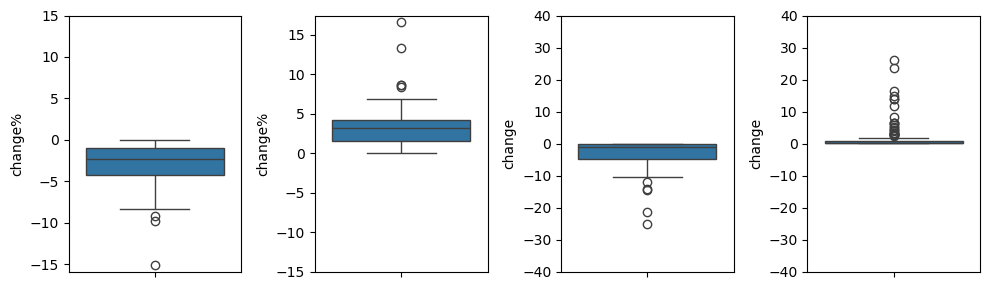

In [72]:
import seaborn as sns
fig, ax = plt.subplots(1,4, figsize=(10,3))
sns.boxplot(ch1.loc[ch1['change%'] < 0, 'change%'], ax=ax[0])
sns.boxplot(ch1.loc[ch1['change%'] > 0, 'change%'], ax=ax[1])
sns.boxplot(ch1.loc[ch1['change'] < 0, 'change'], ax=ax[2])
sns.boxplot(ch1.loc[ch1['change'] > 0, 'change'], ax=ax[3])
ax[0].set_ylim(top=15.0)
ax[1].set_ylim(bottom=-15.0)
ax[2].set_ylim(top=40.0, bottom=-40.0)
ax[3].set_ylim(bottom=-40, top=40)
plt.tight_layout()
plt.show()

In [75]:
# ratio between emisison reduction vs increase
print('Total reduction: ', ch1.loc[ch1['change%'] < 0, 'change%'].sum())
print('Total increase: ', ch1.loc[ch1['change%'] > 0, 'change%'].sum())
print('Difference: ', ch1.loc[ch1['change%'] < 0, 'change%'].sum() + ch1.loc[ch1['change%'] > 0, 'change%'].sum())
print('Median of reduction percentage: ', ch1.loc[ch1['change%'] < 0, 'change%'].median())
print('Q1 of reduction percentage: ', ch1.loc[ch1['change%'] < 0, 'change%'].quantile(0.25))
print('Q3 of reduction percentage: ', ch1.loc[ch1['change%'] < 0, 'change%'].quantile(0.75))

Total reduction:  -149.70999999999998
Total increase:  517.67
Difference:  367.96
Median of reduction percentage:  -2.275
Q1 of reduction percentage:  -4.175
Q3 of reduction percentage:  -0.945


#### Emission  
emission disparity between rich and poor

#### Income

In [105]:
q = """SELECT entity, year, emissions_total FROM owid
WHERE entity IN ('Asia', 'European Union (28)', 'Low-income countries','High-income countries', 'Upper-middle-income countries','Lower-middle-income countries', 'North America')
AND
year > 1940;"""
owid = query(q)

In [106]:
owid.entity.unique()

array(['Asia', 'European Union (28)', 'High-income countries',
       'Low-income countries', 'Lower-middle-income countries',
       'North America', 'Upper-middle-income countries'], dtype=object)

In [117]:
ow_pivot = owid.pivot(columns='entity', index='year', values='emissions_total')
geo = ['Asia', 'European Union (28)', 'North America']
eco = ['High-income countries','Low-income countries', 'Upper-middle-income countries','Lower-middle-income countries']

<Axes: xlabel='year'>

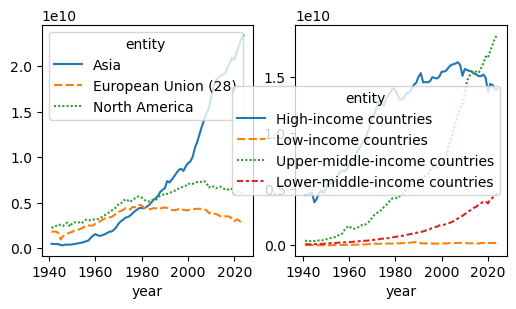

In [118]:
fig, ax = plt.subplots(1,2, figsize=(6,3))
sns.lineplot(ow_pivot[geo], ax=ax[0])
sns.lineplot(ow_pivot[eco], ax=ax[1])

#### usa

In [5]:
q = """SELECT year, emissions_total FROM couns_full WHERE code = 'USA'"""
usa = query(q)

In [14]:
#usa peak emission
usa.loc[usa.emissions_total == usa.emissions_total.max()]

,year,emissions_total
205,2005,6.126903e+09


In [15]:
#usa last emission reduction to peak
usa.loc[usa.year == usa.year.max(), 'emissions_total'] / usa.emissions_total.max()

224    0.800424
Name: emissions_total, dtype: float64

#### Temperature

In [3]:
q = """SELECT sql from sqlite_master"""
print(query(q,source='Global_temperature_change_1850-2026.sql').values[0][0])

CREATE TABLE "temp" (
"Entity" TEXT,
  "Code" TEXT,
  "Year" INTEGER,
  "Average" REAL,
  "Lower bound" REAL,
  "Upper bound" REAL
)


In [4]:
q = """SELECT Entity as ent, Year as year,
Average as avg from temp """
temp = query(q,source='Global_temperature_change_1850-2026.sql')

In [7]:
# temp over 1.5C
temp.loc[temp.avg > 1.5]

,ent,year,avg
165,Northern Hemisphere,2015,1.512106
166,Northern Hemisphere,2016,1.633699
169,Northern Hemisphere,2019,1.542857
170,Northern Hemisphere,2020,1.666524
173,Northern Hemisphere,2023,1.810943
174,Northern Hemisphere,2024,1.917787
175,Northern Hemisphere,2025,1.719785
176,Northern Hemisphere,2026,1.696456
528,World,2024,1.532965


In [5]:
q = """SELECT Year as year,
Average as avg from temp WHERE Entity == 'World' """
inc = query(q,source='Global_temperature_change_1850-2026.sql')

In [6]:
# difference between years
inc['diff'] = inc.avg - inc.avg.shift(1)

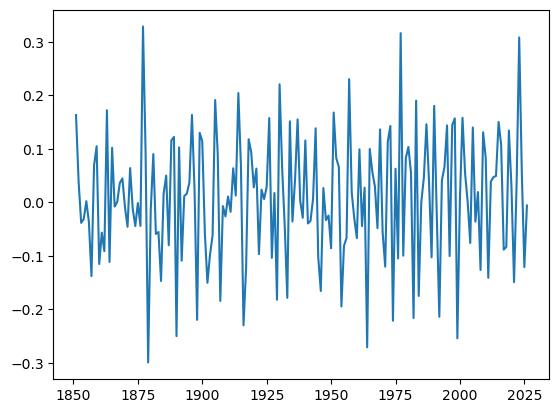

In [7]:
# yearly change distribution
plt.plot(inc.year, inc['diff']);

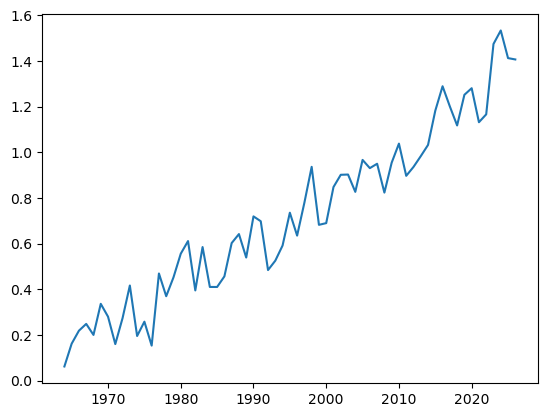

In [8]:
#global warming trend
plt.plot(inc.loc[inc.year > 1963, 'year'], inc.loc[inc.year > 1963, 'avg'])

In [10]:
# narrowing to global warming trend
diff = inc.loc[inc.year > 1963].copy()
diff.reset_index(drop=True, inplace=True)

In [11]:
diff[:3]

,year,avg,diff
0,1964,0.061841,-0.270716
1,1965,0.161662,0.099821
2,1966,0.218596,0.056935


In [50]:
#how much the world got hoter in average in a year between `63 and `24
np.round(((diff[-1:]['avg'].values - diff.loc[:1, 'avg'].values) / diff.shape[0]), 2)

array([0.04])